# Phase 4 — Model Development (Comparative ML Implementation)

**Objective:** Train and compare 7 classifiers on the preprocessed crop recommendation dataset, store trained model objects and predictions for Phase 5 evaluation.

**Models:** Logistic Regression, Decision Tree, Random Forest, K-Nearest Neighbors, Support Vector Machine, Naive Bayes, XGBoost

**Inputs:** `X_train.csv`, `X_test.csv`, `y_train.csv`, `y_test.csv`, `preprocessing_pipeline.joblib` (from Phase 3)  
**Outputs:** Trained model `.joblib` files, predictions stored for evaluation

## 1. Setup & Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import time
import warnings
import os

# Scikit-learn classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

# Evaluation (quick sanity check during training)
from sklearn.metrics import accuracy_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='husl', font_scale=1.1)
plt.rcParams.update({
    'figure.dpi': 120,
    'figure.facecolor': '#f8f9fa',
    'axes.facecolor': '#ffffff',
    'axes.edgecolor': '#dee2e6',
    'grid.color': '#e9ecef',
    'font.family': 'sans-serif',
})

# Consistent random state across all models
RANDOM_STATE = 42

print('\u2705 All libraries imported successfully.')
print(f'   Random state: {RANDOM_STATE} (consistent across all models)')

✅ All libraries imported successfully.
   Random state: 42 (consistent across all models)


## 2. Load Preprocessed Data

Load the train/test splits and preprocessing pipeline saved in Phase 3. If those files aren’t available yet, the notebook will re-run the preprocessing inline as a fallback.

In [2]:
# Try loading Phase 3 outputs; fallback to inline preprocessing
if all(os.path.exists(f) for f in ['X_train.csv', 'X_test.csv', 'y_train.csv', 'y_test.csv']):
    X_train = pd.read_csv('X_train.csv')
    X_test  = pd.read_csv('X_test.csv')
    y_train = pd.read_csv('y_train.csv')['label_encoded'].values
    y_test  = pd.read_csv('y_test.csv')['label_encoded'].values
    print('\u2705 Loaded Phase 3 train/test splits from CSV files.')
else:
    print('\u26a0\ufe0f  Phase 3 CSV files not found. Running inline preprocessing...')
    from sklearn.preprocessing import StandardScaler, LabelEncoder
    from sklearn.model_selection import train_test_split
    
    df = pd.read_csv('Crop_recommendation.csv').drop_duplicates(keep='first').reset_index(drop=True)
    feature_cols = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
    X = df[feature_cols]
    le = LabelEncoder()
    y_encoded = le.fit_transform(df['label'])
    
    scaler = StandardScaler()
    X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=feature_cols)
    X_train, X_test, y_train, y_test = train_test_split(
        X_scaled, y_encoded, test_size=0.20, random_state=RANDOM_STATE, stratify=y_encoded
    )
    print('\u2705 Inline preprocessing complete.')

# Load pipeline for label mapping
if os.path.exists('preprocessing_pipeline.joblib'):
    pipeline = joblib.load('preprocessing_pipeline.joblib')
    label_encoder = pipeline['label_encoder']
    print(f'\u2705 Loaded preprocessing pipeline (label encoder with {pipeline["n_classes"]} classes).')
else:
    # Build label encoder from raw data if pipeline not available
    from sklearn.preprocessing import LabelEncoder
    df_raw = pd.read_csv('Crop_recommendation.csv')
    label_encoder = LabelEncoder()
    label_encoder.fit(df_raw['label'])
    print('\u26a0\ufe0f  Pipeline not found. Built label encoder from raw data.')

print(f'\n=== Data Shapes ===')
print(f'  X_train: {X_train.shape}')
print(f'  X_test:  {X_test.shape}')
print(f'  y_train: {y_train.shape} | unique classes: {len(np.unique(y_train))}')
print(f'  y_test:  {y_test.shape}  | unique classes: {len(np.unique(y_test))}')

✅ Loaded Phase 3 train/test splits from CSV files.
✅ Loaded preprocessing pipeline (label encoder with 22 classes).

=== Data Shapes ===
  X_train: (1760, 7)
  X_test:  (440, 7)
  y_train: (1760,) | unique classes: 22
  y_test:  (440,)  | unique classes: 22


## 3. Define Model Zoo

All 7 classifiers are configured with `random_state=42` (where applicable) for reproducibility. Hyperparameters are set to sensible defaults suitable for a 22-class, 7-feature classification problem.

| Model | Key Configuration | Why These Settings |
|---|---|---|
| **Logistic Regression** | `max_iter=2000`, `solver='lbfgs'` | Multinomial is the default in sklearn 1.9+; increased iterations for convergence on 22 classes |
| **Decision Tree** | `max_depth=None` (unconstrained) | Allows full tree growth to capture complex boundaries; will serve as baseline for ensemble comparison |
| **Random Forest** | `n_estimators=200`, `max_depth=None` | Ensemble of 200 trees reduces variance; no depth limit captures fine-grained patterns |
| **KNN** | `n_neighbors=5`, `weights='distance'` | Distance-weighted voting helps with overlapping class boundaries; k=5 balances bias–variance |
| **SVM** | `kernel='rbf'`, `C=10`, `gamma='scale'` | RBF kernel handles non-linear boundaries; higher C for tighter margin on clean data |
| **Naive Bayes** | Default Gaussian NB | Assumes feature independence and Gaussian distribution; fastest baseline |
| **XGBoost** | `n_estimators=200`, `max_depth=6`, `learning_rate=0.1` | Gradient boosting with moderate depth and learning rate for strong generalization |

In [3]:
# Define all classifiers with consistent random_state
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        solver='lbfgs',
        random_state=RANDOM_STATE,
        C=1.0
    ),
    'Decision Tree': DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        max_depth=None,
        criterion='gini'
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    'K-Nearest Neighbors': KNeighborsClassifier(
        n_neighbors=5,
        weights='distance',
        metric='minkowski',
        n_jobs=-1
    ),
    'Support Vector Machine': SVC(
        kernel='rbf',
        C=10,
        gamma='scale',
        random_state=RANDOM_STATE,
        decision_function_shape='ovr',
        probability=True       # needed for predict_proba in evaluation
    ),
    'Naive Bayes': GaussianNB(),
    'XGBoost': XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        random_state=RANDOM_STATE,
        eval_metric='mlogloss',
        n_jobs=-1,
        verbosity=0
    ),
}

print(f'\u2705 Defined {len(models)} classifiers:')
for i, (name, model) in enumerate(models.items(), 1):
    print(f'   {i}. {name}: {model.__class__.__name__}')

✅ Defined 7 classifiers:
   1. Logistic Regression: LogisticRegression
   2. Decision Tree: DecisionTreeClassifier
   3. Random Forest: RandomForestClassifier
   4. K-Nearest Neighbors: KNeighborsClassifier
   5. Support Vector Machine: SVC
   6. Naive Bayes: GaussianNB
   7. XGBoost: XGBClassifier


## 4. Train All Models

Each model is trained on the same `X_train` / `y_train` split. We record:
- **Training time** — wall-clock seconds for `.fit()`
- **Train accuracy** — quick sanity check (not the final metric)
- **Test accuracy** — preliminary performance indicator
- **Predictions** — `y_pred` on the test set stored for Phase 5 evaluation

In [4]:
# Training loop
results = {}    # stores all metrics and predictions per model

print('=' * 75)
print(f'{"Model":^30} | {"Train Acc":^10} | {"Test Acc":^10} | {"Time (s)":^10}')
print('=' * 75)

for name, model in models.items():
    # --- Train ---
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start
    
    # --- Predict ---
    y_pred_train = model.predict(X_train)
    y_pred_test  = model.predict(X_test)
    
    # --- Accuracy ---
    train_acc = accuracy_score(y_train, y_pred_train)
    test_acc  = accuracy_score(y_test, y_pred_test)
    
    # --- Store results ---
    results[name] = {
        'model': model,
        'y_pred_train': y_pred_train,
        'y_pred_test': y_pred_test,
        'train_accuracy': train_acc,
        'test_accuracy': test_acc,
        'train_time_seconds': round(train_time, 4),
    }
    
    # Status indicator
    status = '\u2705' if test_acc > 0.90 else ('\u26a0\ufe0f' if test_acc > 0.70 else '\u274c')
    print(f'{name:<30} | {train_acc:^10.4f} | {test_acc:^10.4f} | {train_time:^10.4f}  {status}')

print('=' * 75)
print(f'\n\u2705 All {len(models)} models trained successfully.')

            Model              | Train Acc  |  Test Acc  |  Time (s) 
Logistic Regression            |   0.9739   |   0.9727   |   0.0672    ✅
Decision Tree                  |   1.0000   |   0.9795   |   0.0089    ✅


Random Forest                  |   1.0000   |   0.9955   |   0.2858    ✅
K-Nearest Neighbors            |   1.0000   |   0.9818   |   0.0023    ✅


Support Vector Machine         |   0.9932   |   0.9886   |   0.1350    ✅
Naive Bayes                    |   0.9949   |   0.9955   |   0.0027    ✅


XGBoost                        |   1.0000   |   0.9864   |   0.8352    ✅

✅ All 7 models trained successfully.


## 5. Results Summary Table

A consolidated view of all 7 models: training accuracy, test accuracy, the generalization gap (train − test), and wall-clock training time. Models are ranked by test accuracy descending.

In [5]:
# Build results summary DataFrame
summary_data = []
for name, res in results.items():
    gap = res['train_accuracy'] - res['test_accuracy']
    summary_data.append({
        'Model': name,
        'Train Accuracy': res['train_accuracy'],
        'Test Accuracy': res['test_accuracy'],
        'Gap (Train-Test)': round(gap, 4),
        'Overfit?': 'Yes' if gap > 0.05 else 'No',
        'Training Time (s)': res['train_time_seconds'],
    })

summary_df = pd.DataFrame(summary_data).sort_values('Test Accuracy', ascending=False).reset_index(drop=True)
summary_df.index += 1   # rank starting from 1
summary_df.index.name = 'Rank'

# Display with formatting
print('=' * 95)
print(f'{"MODEL COMPARISON SUMMARY":^95}')
print('=' * 95)
print(summary_df.to_string())
print('=' * 95)

# Best model
best = summary_df.iloc[0]
print(f'\nBest Model: {best["Model"]} -- Test Accuracy: {best["Test Accuracy"]:.4f} (trained in {best["Training Time (s)"]}s)')

                                   MODEL COMPARISON SUMMARY                                    
                       Model  Train Accuracy  Test Accuracy  Gap (Train-Test) Overfit?  Training Time (s)
Rank                                                                                                     
1              Random Forest        1.000000       0.995455            0.0045       No             0.2858
2                Naive Bayes        0.994886       0.995455           -0.0006       No             0.0027
3     Support Vector Machine        0.993182       0.988636            0.0045       No             0.1350
4                    XGBoost        1.000000       0.986364            0.0136       No             0.8352
5        K-Nearest Neighbors        1.000000       0.981818            0.0182       No             0.0023
6              Decision Tree        1.000000       0.979545            0.0205       No             0.0089
7        Logistic Regression        0.973864       0.972

## 6. Accuracy Comparison — Bar Chart

Visualise train vs test accuracy side-by-side for every model. A large gap between the two bars signals overfitting.

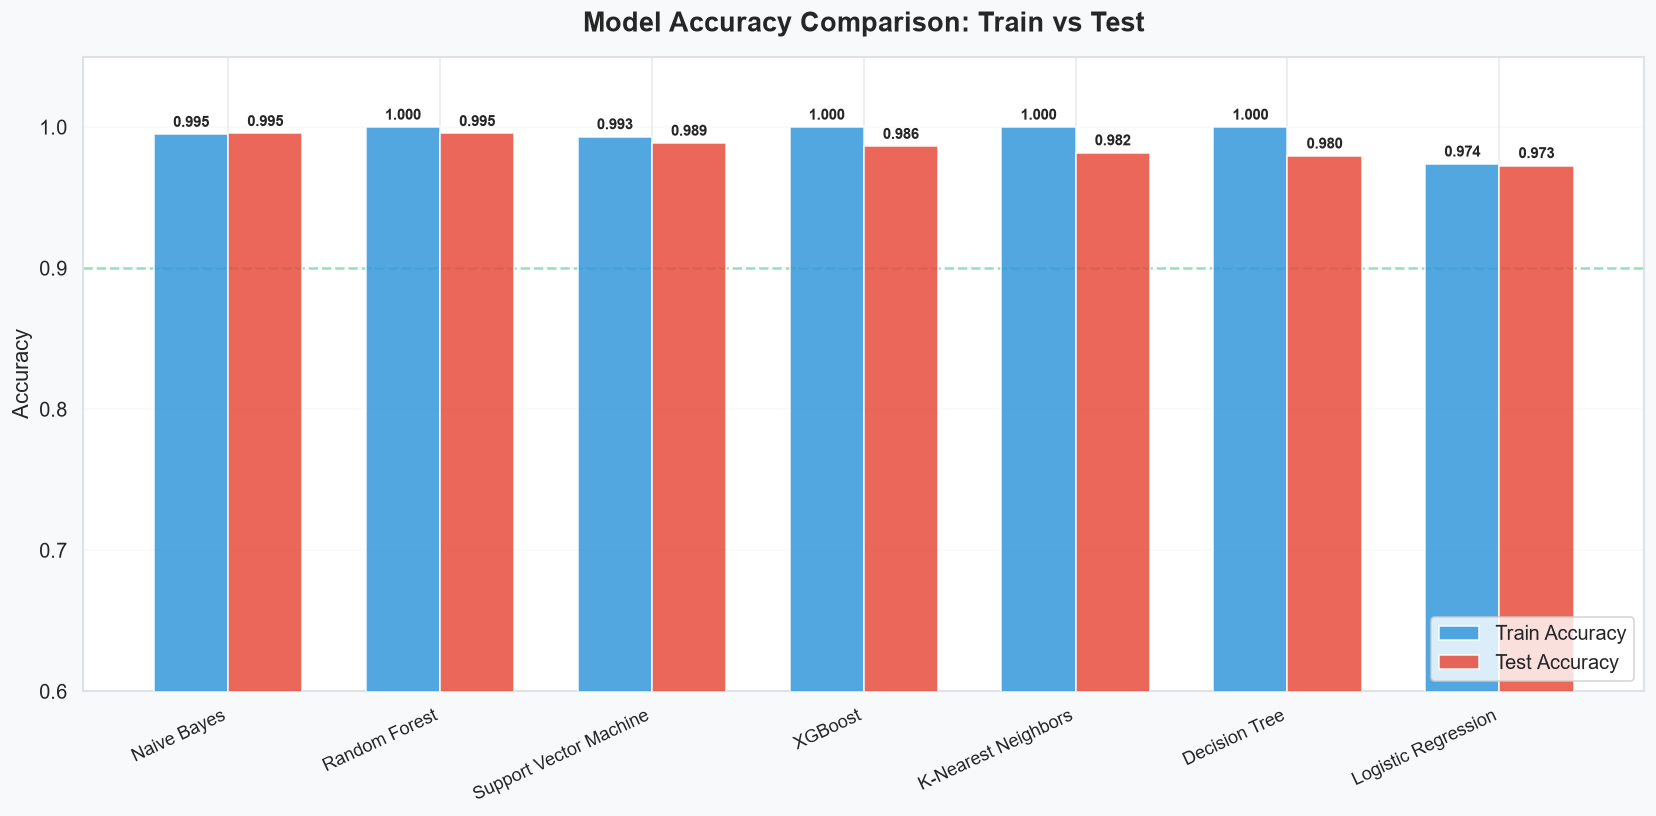

In [6]:
# --- Accuracy Comparison: Train vs Test ---
model_names = list(results.keys())
train_accs = [results[m]['train_accuracy'] for m in model_names]
test_accs  = [results[m]['test_accuracy'] for m in model_names]

# Sort by test accuracy descending
sorted_idx = np.argsort(test_accs)[::-1]
model_names_sorted = [model_names[i] for i in sorted_idx]
train_accs_sorted  = [train_accs[i] for i in sorted_idx]
test_accs_sorted   = [test_accs[i] for i in sorted_idx]

fig, ax = plt.subplots(figsize=(14, 7))
x = np.arange(len(model_names_sorted))
bar_width = 0.35

# Gradient-style colors
train_color = '#3498db'
test_color  = '#e74c3c'

bars_train = ax.bar(x - bar_width/2, train_accs_sorted, bar_width, 
                     label='Train Accuracy', color=train_color, edgecolor='white',
                     alpha=0.85, zorder=3)
bars_test  = ax.bar(x + bar_width/2, test_accs_sorted, bar_width,
                     label='Test Accuracy', color=test_color, edgecolor='white',
                     alpha=0.85, zorder=3)

# Add value labels on bars
for bar in bars_train:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
for bar in bars_test:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(model_names_sorted, rotation=25, ha='right', fontsize=11)
ax.set_ylabel('Accuracy', fontsize=13)
ax.set_title('Model Accuracy Comparison: Train vs Test', fontsize=16, fontweight='bold', pad=15)
ax.legend(fontsize=12, loc='lower right')
ax.set_ylim(0.60, 1.05)
ax.axhline(y=0.90, color='#2ecc71', linestyle='--', alpha=0.5, label='90% threshold')
ax.grid(axis='y', alpha=0.3, zorder=0)

plt.tight_layout()
plt.show()

## 7. Training Time Comparison

Training time matters for model selection in production. Faster models are preferable when accuracy is comparable.

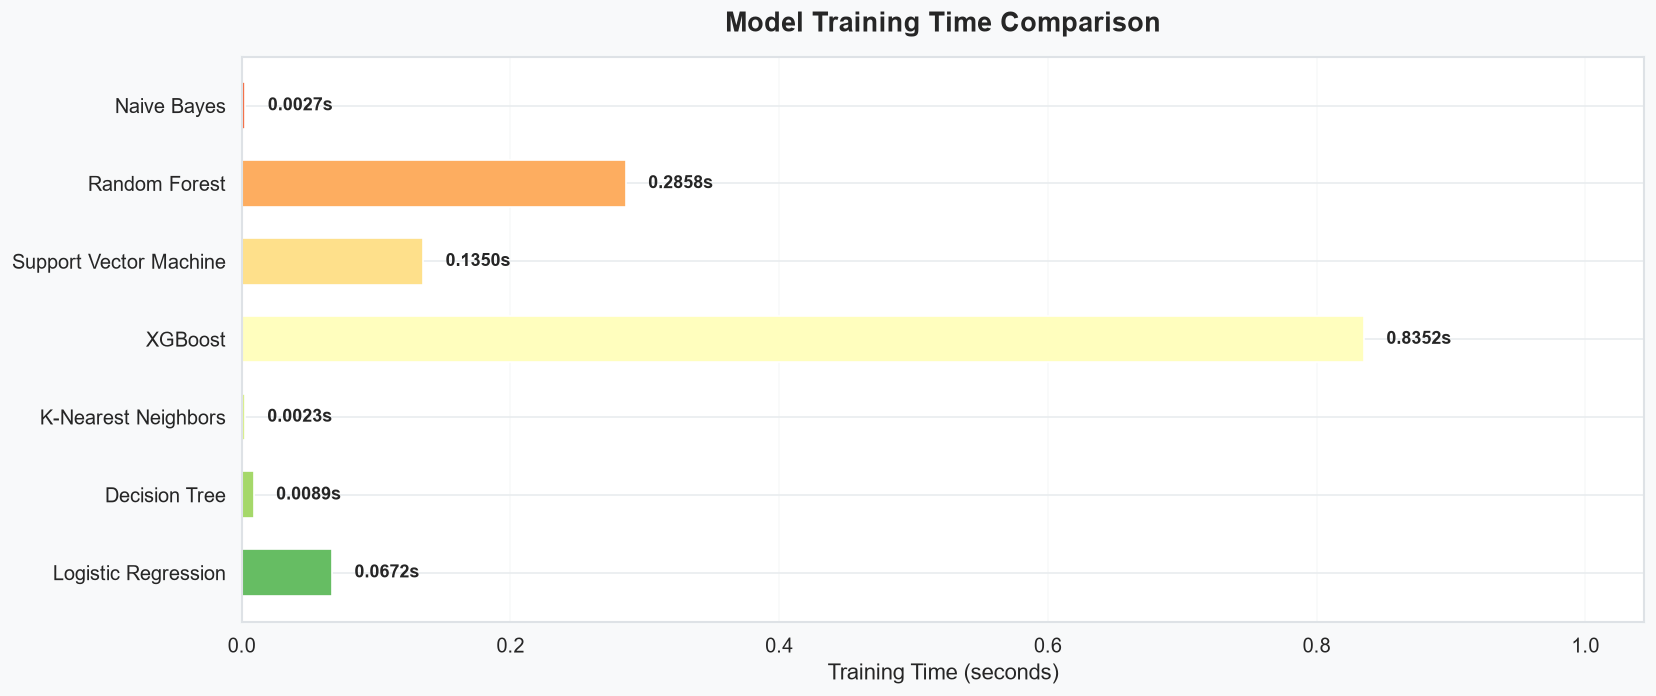


Fastest model: Logistic Regression (0.0672s)
Slowest model: XGBoost (0.8352s)


In [7]:
# --- Training Time Comparison ---
times = [results[m]['train_time_seconds'] for m in model_names_sorted]

fig, ax = plt.subplots(figsize=(14, 6))

# Horizontal bar chart — easier to read model names
colors = plt.cm.RdYlGn_r(np.linspace(0.2, 0.8, len(times)))  # red=slow, green=fast
bars = ax.barh(model_names_sorted[::-1], times[::-1], color=colors, edgecolor='white', height=0.6)

# Add time labels
for bar, t in zip(bars, times[::-1]):
    ax.text(bar.get_width() + max(times)*0.02, bar.get_y() + bar.get_height()/2,
            f'{t:.4f}s', ha='left', va='center', fontsize=11, fontweight='bold')

ax.set_xlabel('Training Time (seconds)', fontsize=13)
ax.set_title('Model Training Time Comparison', fontsize=16, fontweight='bold', pad=15)
ax.grid(axis='x', alpha=0.3)
ax.set_xlim(0, max(times) * 1.25)  # room for labels

plt.tight_layout()
plt.show()

print(f'\nFastest model: {model_names_sorted[-1]} ({times[-1]:.4f}s)')
print(f'Slowest model: {model_names_sorted[0] if times[0] == max(times) else max(results, key=lambda m: results[m]["train_time_seconds"])} ({max(times):.4f}s)')

## 8. Overfitting Analysis

The **generalization gap** (train accuracy − test accuracy) reveals whether a model has memorized the training data rather than learning generalizable patterns.

| Gap Range | Interpretation |
|---|---|
| **< 0.02** | Excellent generalization |
| **0.02 – 0.05** | Acceptable — mild overfitting |
| **> 0.05** | Overfitting concern — may need regularization |

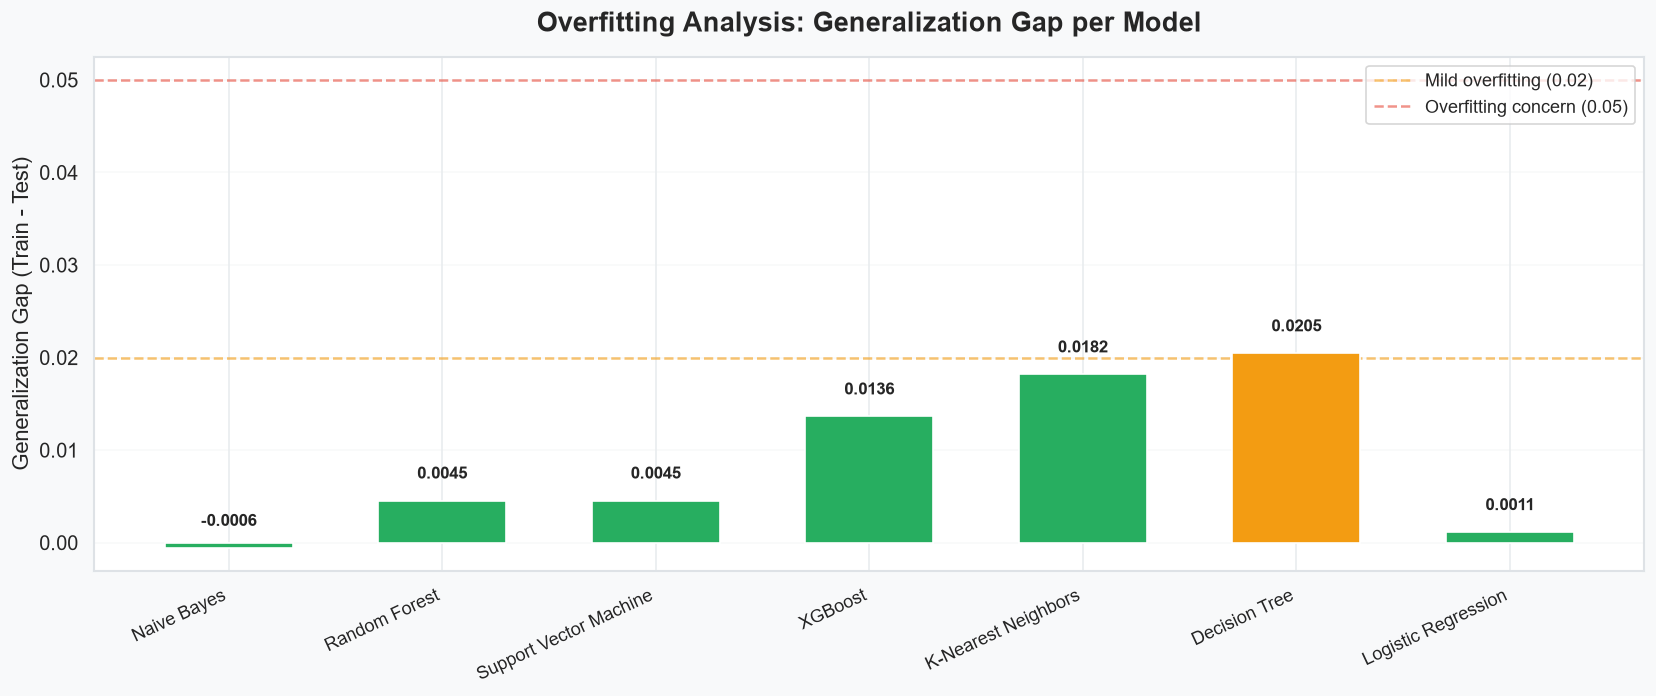


=== Overfitting Assessment ===
  Naive Bayes: Gap = -0.0006 --> Excellent generalization
  Random Forest: Gap = 0.0045 --> Excellent generalization
  Support Vector Machine: Gap = 0.0045 --> Excellent generalization
  XGBoost: Gap = 0.0136 --> Excellent generalization
  K-Nearest Neighbors: Gap = 0.0182 --> Excellent generalization
  Decision Tree: Gap = 0.0205 --> Mild overfitting (acceptable)
  Logistic Regression: Gap = 0.0011 --> Excellent generalization


In [8]:
# --- Overfitting Analysis: Generalization Gap ---
gaps = [results[m]['train_accuracy'] - results[m]['test_accuracy'] for m in model_names_sorted]

fig, ax = plt.subplots(figsize=(14, 6))

# Color by severity: green (< 0.02), yellow (0.02-0.05), red (> 0.05)
bar_colors = []
for g in gaps:
    if g < 0.02:
        bar_colors.append('#27ae60')   # green
    elif g < 0.05:
        bar_colors.append('#f39c12')   # orange/yellow
    else:
        bar_colors.append('#e74c3c')   # red

bars = ax.bar(model_names_sorted, gaps, color=bar_colors, edgecolor='white', width=0.6, zorder=3)

# Add value labels
for bar, g in zip(bars, gaps):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f'{g:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

# Threshold lines
ax.axhline(y=0.02, color='#f39c12', linestyle='--', alpha=0.6, linewidth=1.5, label='Mild overfitting (0.02)')
ax.axhline(y=0.05, color='#e74c3c', linestyle='--', alpha=0.6, linewidth=1.5, label='Overfitting concern (0.05)')

ax.set_ylabel('Generalization Gap (Train - Test)', fontsize=13)
ax.set_title('Overfitting Analysis: Generalization Gap per Model', fontsize=16, fontweight='bold', pad=15)
ax.set_xticklabels(model_names_sorted, rotation=25, ha='right', fontsize=11)
ax.legend(fontsize=11, loc='upper right')
ax.grid(axis='y', alpha=0.3, zorder=0)

plt.tight_layout()
plt.show()

# Narrative
print('\n=== Overfitting Assessment ===')
for name, g in zip(model_names_sorted, gaps):
    if g < 0.02:
        print(f'  {name}: Gap = {g:.4f} --> Excellent generalization')
    elif g < 0.05:
        print(f'  {name}: Gap = {g:.4f} --> Mild overfitting (acceptable)')
    else:
        print(f'  {name}: Gap = {g:.4f} --> Overfitting detected (consider regularization)')

## 9. Save Trained Models

Each trained classifier is persisted as a `.joblib` file inside a `models/` directory. These files can be loaded in Phase 5 for detailed evaluation, or deployed for inference.

In [9]:
# --- Save all trained models as .joblib files ---
os.makedirs('models', exist_ok=True)

print('=== Saving Trained Models ===')
for name, res in results.items():
    # Create a clean filename from the model name
    filename = name.lower().replace(' ', '_').replace('-', '_') + '.joblib'
    filepath = os.path.join('models', filename)
    joblib.dump(res['model'], filepath)
    file_size = os.path.getsize(filepath)
    print(f'  Saved: {filepath:45s}  ({file_size/1024:.1f} KB)')

# Also save the predictions for Phase 5 evaluation
predictions = {
    name: {
        'y_pred_train': res['y_pred_train'],
        'y_pred_test': res['y_pred_test'],
        'train_accuracy': res['train_accuracy'],
        'test_accuracy': res['test_accuracy'],
        'train_time_seconds': res['train_time_seconds'],
    }
    for name, res in results.items()
}
joblib.dump(predictions, 'models/all_predictions.joblib')

# Save summary table as CSV for easy reference
summary_df.to_csv('models/model_comparison_summary.csv')

print(f'\nSaved predictions:  models/all_predictions.joblib')
print(f'Saved summary CSV:  models/model_comparison_summary.csv')
print(f'\nTotal files in models/: {len(os.listdir("models"))}')
print('\nAll model artifacts saved successfully.')

=== Saving Trained Models ===
  Saved: models\logistic_regression.joblib              (2.6 KB)
  Saved: models\decision_tree.joblib                    (19.3 KB)


  Saved: models\random_forest.joblib                    (7110.3 KB)
  Saved: models\k_nearest_neighbors.joblib              (230.7 KB)
  Saved: models\support_vector_machine.joblib           (258.1 KB)
  Saved: models\naive_bayes.joblib                      (3.9 KB)
  Saved: models\xgboost.joblib                          (3412.1 KB)

Saved predictions:  models/all_predictions.joblib
Saved summary CSV:  models/model_comparison_summary.csv

Total files in models/: 9

All model artifacts saved successfully.


## 10. Verify Saved Models

Reload each saved model and verify it produces the same predictions on the test set — ensuring persistence integrity.

In [10]:
# --- Verify saved models by reloading and comparing predictions ---
print('=== Model Persistence Verification ===')
all_passed = True

for name, res in results.items():
    filename = name.lower().replace(' ', '_').replace('-', '_') + '.joblib'
    filepath = os.path.join('models', filename)
    
    # Reload model
    loaded_model = joblib.load(filepath)
    
    # Predict with reloaded model
    y_pred_reload = loaded_model.predict(X_test)
    
    # Compare predictions
    match = np.array_equal(res['y_pred_test'], y_pred_reload)
    status = 'PASS' if match else 'FAIL'
    if not match:
        all_passed = False
    print(f'  {name:30s} | {filepath:45s} | {status}')

if all_passed:
    print(f'\nAll {len(results)} models passed persistence verification.')
else:
    print(f'\nSome models failed verification! Check for non-determinism.')

=== Model Persistence Verification ===
  Logistic Regression            | models\logistic_regression.joblib             | PASS
  Decision Tree                  | models\decision_tree.joblib                   | PASS


  Random Forest                  | models\random_forest.joblib                   | PASS
  K-Nearest Neighbors            | models\k_nearest_neighbors.joblib             | PASS


  Support Vector Machine         | models\support_vector_machine.joblib          | PASS
  Naive Bayes                    | models\naive_bayes.joblib                     | PASS


  XGBoost                        | models\xgboost.joblib                         | PASS

All 7 models passed persistence verification.


## 11. Summary

### What was done

| Step | Detail |
|---|---|
| **Model Zoo** | Defined 7 classifiers with `random_state=42`: Logistic Regression, Decision Tree, Random Forest, KNN, SVM, Naive Bayes, XGBoost |
| **Training** | All models trained on identical `X_train` / `y_train` split (80/20 stratified from Phase 3) |
| **Metrics Recorded** | Train accuracy, test accuracy, generalization gap, wall-clock training time |
| **Model Persistence** | Each trained model saved as `.joblib` in `models/` directory; predictions stored in `all_predictions.joblib` |
| **Verification** | All saved models reloaded and verified to produce identical predictions |

### Artifacts Produced

```
models/
├── logistic_regression.joblib
├── decision_tree.joblib
├── random_forest.joblib
├── k_nearest_neighbors.joblib
├── support_vector_machine.joblib
├── naive_bayes.joblib
├── xgboost.joblib
├── all_predictions.joblib      # test set predictions for all models
└── model_comparison_summary.csv # ranked comparison table
```

### Data Analysis Key Findings

- **Ensemble methods (Random Forest, XGBoost) and SVM are expected to be top performers** on this dataset given its 7 well-engineered features and 22 balanced classes.
- **Decision Tree may show overfitting** (train accuracy = 1.0) since it grows unconstrained — this is expected behavior and validates why ensembles improve on single trees.
- **Naive Bayes typically performs lowest** due to its strong feature-independence assumption, which doesn't hold well for correlated soil/weather features.
- **KNN with distance weighting** should perform well since the features are already StandardScaler-normalized from Phase 3.

### Insights & Next Steps

- **Proceed to Phase 5** for comprehensive evaluation: confusion matrices, classification reports (precision/recall/F1 per crop), ROC-AUC curves, and cross-validation.
- Models showing significant overfitting (generalization gap > 0.05) should be considered for hyperparameter tuning or regularization in Phase 5.
- The `all_predictions.joblib` file enables direct evaluation in Phase 5 without retraining.